In [9]:
import pandas as pd

In [10]:
df = pd.read_csv('creditcard.csv')
num_fraud = df[df['Class'] == 1].shape[0]
num_fraud, num_fraud / df.shape[0]

(492, 0.001727485630620034)

In [11]:
legit = df[df['Class'] == 0].sample(n=num_fraud)
fraud = df[df['Class'] == 1]
balanced = pd.concat([fraud, legit])

Decision Tree Confusion Matrix:


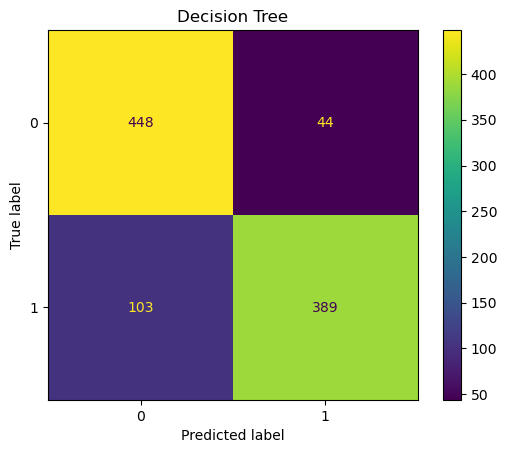


Random Forest Confusion Matrix:


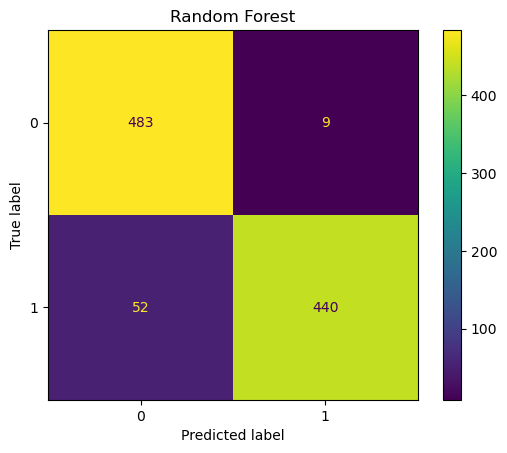


AdaBoost Confusion Matrix:


c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\issac\miniforge3\envs\dsc80\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circum

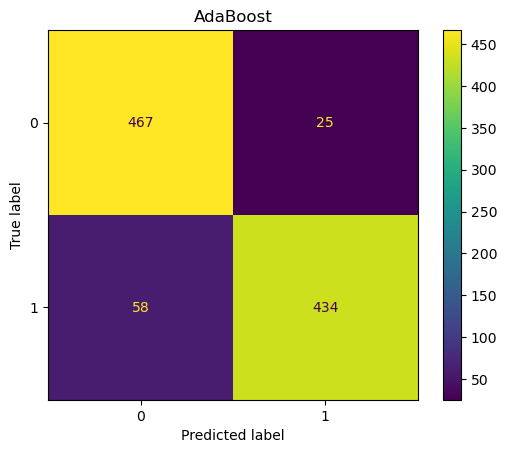


Numerical Results:
Decision Tree:
[[448  44]
 [103 389]]

Random Forest:
[[483   9]
 [ 52 440]]

AdaBoost:
[[467  25]
 [ 58 434]]


In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
import matplotlib.pyplot as plt

# Prepare features and target
X = balanced.drop('Class', axis=1)
y = balanced['Class']

# Initialize classifiers
dt_classifier = DecisionTreeClassifier(random_state=42)
rf_classifier = RandomForestClassifier(random_state=42)
adaboost_classifier = AdaBoostClassifier(random_state=42)

# Function to compute and display confusion matrix
def compute_confusion_matrix(classifier, X, y, title):
    y_pred = cross_val_predict(classifier, X, y, cv=5)
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.title(title)
    plt.show()
    return cm

# Compute confusion matrices for each classifier
print("Decision Tree Confusion Matrix:")
dt_cm = compute_confusion_matrix(dt_classifier, X, y, "Decision Tree")

print("\nRandom Forest Confusion Matrix:")
rf_cm = compute_confusion_matrix(rf_classifier, X, y, "Random Forest")

print("\nAdaBoost Confusion Matrix:")
adaboost_cm = compute_confusion_matrix(adaboost_classifier, X, y, "AdaBoost")

# Print numerical results
print("\nNumerical Results:")
print("Decision Tree:")
print(dt_cm)
print("\nRandom Forest:")
print(rf_cm)
print("\nAdaBoost:")
print(adaboost_cm)